#### Task 1: Predict Restaurant Ratings

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("Dataset .csv")

print("Dataset loaded successfully.")
print("Dataset Shape:", df.shape)

Dataset loaded successfully.
Dataset Shape: (9551, 21)


##### 2. Dataset Inspection

In [ ]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())

Column Names:
['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu', 'Price range', 'Aggregate rating', 'Rating color', 'Rating text', 'Votes']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   L

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


##### 3. Data Preprocessing

In [ ]:

print("Missing values before preprocessing:")
print(df.isnull().sum())

df["Cuisines"] = df["Cuisines"].fillna("Unknown")

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

Missing values before preprocessing:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Missing values after preprocessing:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is 

##### 4. Target Variable and Feature Selection

In [ ]:

target = "Aggregate rating"

columns_to_remove = [
    "Aggregate rating",
    "Rating color",
    "Rating text"
]

X = df.drop(columns=columns_to_remove)
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (9551, 18)
Target shape: (9551,)


##### 5. Identify Categorical and Numerical Variables

In [6]:

categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()

numerical_columns = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']

Numerical columns:
['Restaurant ID', 'Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']


##### 6. Encode Categorical Variables


In [ ]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

# Transform the features
X_encoded = preprocessor.fit_transform(X)

print("Original feature shape:", X.shape)
print("Encoded feature shape:", X_encoded.shape)

Original feature shape: (9551, 18)
Encoded feature shape: (9551, 20830)


##### 7. Train/Test Split

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (7640, 20830)
Testing data shape: (1911, 20830)

Training target shape: (7640,)
Testing target shape: (1911,)


##### 8. Linear Regression Model

In [10]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


##### 9. Model Evaluation

In [ ]:

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
print("R-squared (R²):", r2)

Mean Squared Error (MSE): 1.757730884431856
R-squared (R²): 0.22774748840438586


##### 10. Actual vs Predicted Ratings

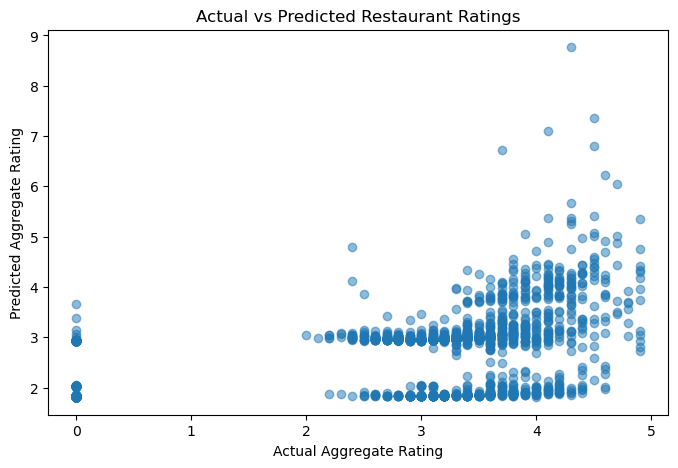

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Aggregate Rating")
plt.ylabel("Predicted Aggregate Rating")
plt.title("Actual vs Predicted Restaurant Ratings")

plt.show()

##### 11. Feature Influence Analysis

In [ ]:

feature_names = preprocessor.get_feature_names_out()

coefficients = model.coef_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Influence"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Influence",
    ascending=False
)

print("Top 10 Most Influential Features:")
display(feature_importance.head(10))

Top 10 Most Influential Features:


,Feature,Coefficient,Absolute Influence
20824,remainder__Country Code,0.006284,0.006284
20825,remainder__Longitude,-0.002626,0.002626
20829,remainder__Votes,0.000772,0.000772
20828,remainder__Price range,0.000113,0.000113
7534,cat__City_New Delhi,-0.000034,0.000034
20808,cat__Currency_Indian Rupees(Rs.),-0.000033,0.000033
20819,cat__Has Online delivery_Yes,0.000032,0.000032
20818,cat__Has Online delivery_No,-0.000032,0.000032
20284,cat__Cuisines_North Indian,-0.000021,0.000021
20806,cat__Currency_Dollar($),0.000020,0.000020


##### 12. Interpretation and Analysis

The Linear Regression model is evaluated using Mean Squared Error (MSE) and R-squared (R²).

The MSE represents the average squared difference between the actual and predicted restaurant ratings. A lower MSE indicates smaller prediction errors.

The R² value indicates how much of the variation in aggregate restaurant ratings is explained by the model.

The feature influence analysis identifies the features with the largest absolute regression coefficients. These features have the greatest influence on the predictions made by the Linear Regression model.

The Actual vs Predicted Ratings plot provides a visual comparison between the actual and predicted ratings and helps in interpreting the model's prediction performance.